In [32]:
from google.colab import drive

# mounting dataset dari gdrive
drive.mount('/content/gdrive', force_remount=True)

# lokasi dataset - ubah sesuai dengan lokasi anda mengupload folder datanya
# folder ini juga digunakan untuk menyimpan model yang sudah dilatih
root_path = '/content/gdrive/MyDrive/Colab Notebooks/Portofolio Data/Analisa Sentimen/'

# opsional - tampilkan info lokasi dataset
print("Path root:", root_path)

Mounted at /content/gdrive
Path root: /content/gdrive/MyDrive/Colab Notebooks/Portofolio Data/Analisa Sentimen/


In [33]:
# import nltk
# from nltk.corpus import stopwords

# nltk.download('stopwords')
# print(stopwords.words('indonesian'))

In [34]:
# Library yang akan digunakan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [35]:
# !pip install twint
# import twint
# import nest_asyncio
# nest_asyncio.apply()


import datetime as dt
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import nltk
nltk.download('punkt_tab')

!pip install Sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from wordcloud import WordCloud

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [36]:
# 1. Membuka file di Google Collab
datafile = root_path + "/updata_data_bersih.xlsx" # Lokasi file

df = pd.read_excel(datafile) # Membuka data tersebut dalam bentuk csv
df

,remove_symbol,result
0,Pak Anies presiden maka Jokowi masuk penjara t...,negatif
1,Ingin tiga priode wkwkwk,negatif
2,Ngakak Kemaren dia berucap sudah mengantongi ...,negatif
3,jokowi tiga priode,negatif
4,Mari jadikan jokowi tiga priode karena beliaul...,positif
...,...,...
118,jabatan klo dipegang seseorang yang mampu pint...,negatif
119,udah cukup kita dibohongin pencitraan selama i...,negatif
120,kalau utang lunas butuh berapa periode YDTKTS,negatif
121,orang dungu yang memimpin butuh 3periode agar ...,positif


In [37]:
def cleaningText(text):
  text = text.replace('\n', ' ')
  text = text.translate(str.maketrans('', '', string.punctuation))
  text = text.strip(' ')
  return text

def caseFolding(text):
  text = text.lower()
  return text

def tokenizingText(text):
  nltk.download('punkt')
  nltk.download('stopwords')
  text = word_tokenize(text)
  return text

def filteringText(text):
  listStopword = set(stopwords.words('indonesian'))
  filtered = []
  for txt in text:
    if txt not in listStopword:
      filtered.append(txt)
  text = filtered
  return text

def stemmingText(text):
  factory = StemmerFactory()
  stemmer = factory.create_stemmer()
  text = [stemmer.stem(word) for word in text]
  return text

def sentenceText(list_word):
  sentence = ' '.join(word for word in list_word)
  return sentence

In [38]:
df['text_clean'] = df['remove_symbol'].apply(cleaningText)
df['text_clean'] = df['remove_symbol'].apply(caseFolding)

df['preprocessing'] = df['text_clean'].apply(tokenizingText)
df['preprocessing'] = df['preprocessing'].apply(filteringText)
df['preprocessing'] = df['preprocessing'].apply(stemmingText)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Packag

In [39]:
df

,remove_symbol,result,text_clean,preprocessing
0,Pak Anies presiden maka Jokowi masuk penjara t...,negatif,pak anies presiden maka jokowi masuk penjara t...,"[anies, presiden, jokowi, masuk, penjara, ting..."
1,Ingin tiga priode wkwkwk,negatif,ingin tiga priode wkwkwk,"[priode, wkwkwk]"
2,Ngakak Kemaren dia berucap sudah mengantongi ...,negatif,ngakak kemaren dia berucap sudah mengantongi ...,"[ngakak, kemaren, ucap, kantong, ratus, triliu..."
3,jokowi tiga priode,negatif,jokowi tiga priode,"[jokowi, priode]"
4,Mari jadikan jokowi tiga priode karena beliaul...,positif,mari jadikan jokowi tiga priode karena beliaul...,"[mari, jadi, jokowi, priode, biau, yg, usung, ..."
...,...,...,...,...
118,jabatan klo dipegang seseorang yang mampu pint...,negatif,jabatan klo dipegang seseorang yang mampu pint...,"[jabat, klo, pegang, pintar, pribadi, pegang, ..."
119,udah cukup kita dibohongin pencitraan selama i...,negatif,udah cukup kita dibohongin pencitraan selama i...,"[udah, dibohongin, citra, bagus, ee, akhir, pe..."
120,kalau utang lunas butuh berapa periode YDTKTS,negatif,kalau utang lunas butuh berapa periode ydtkts,"[utang, lunas, butuh, periode, ydtkts]"
121,orang dungu yang memimpin butuh 3periode agar ...,positif,orang dungu yang memimpin butuh 3periode agar ...,"[orang, dungu, pimpin, butuh, 3periode, yg, pi..."


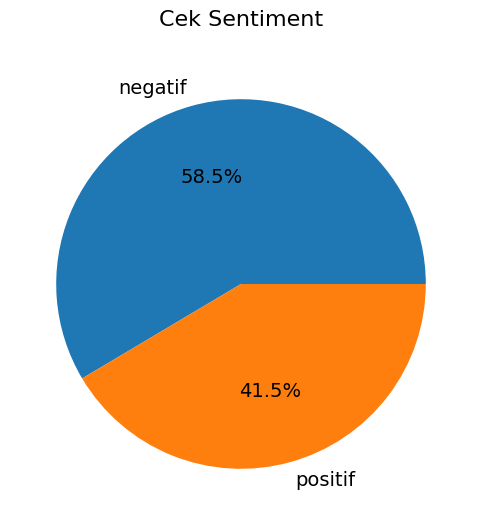

In [40]:
fig, ax = plt.subplots(figsize = (6, 6))
sizes = [count for count in df['result'].value_counts()]

labels = list(df['result'].value_counts().index)
ax.pie(x = sizes, labels = labels, autopct = '%1.1f%%', textprops={'fontsize': 14})
ax.set_title('Cek Sentiment', fontsize = 16, pad = 20)
plt.show()

In [41]:
negative = root_path + "InSet-master/negative.tsv"

# reading given tsv file
csv_table=pd.read_table(negative,sep='\t')

negative_baru = root_path + "InSet-master/negative_baru.csv"
# converting tsv file into csv
csv_table.to_csv(negative_baru,index=False)

# output
print("Successfully made csv file")

Successfully made csv file


In [42]:
import csv

lexicon_positive = dict()
with open(root_path + "InSet-master/positive_baru.csv", 'r') as csvfile:
  reader = csv.reader(csvfile, delimiter=',')
  for row in reader:
    if len(row) >= 2:  # Check if the row has at least two elements
        try:
            lexicon_positive[row[0]] = int(row[1])
        except ValueError:
            print(f"Skipping row: {row} - the second column is not a valid integer.")
    # else:
    #     print(f"Skipping row: {row} does not have at least two columns.")
print(lexicon_positive )

lexicon_negative = dict()
with open(root_path + "InSet-master/negative_baru.csv", 'r') as csvfile:
  reader = csv.reader(csvfile, delimiter=',')
  for row in reader:
    if len(row) >= 2:  # Check if the row has at least two elements
        try:
            lexicon_negative[row[0]] = int(row[1])
        except ValueError:
            print(f"Skipping row: {row} - the second column is not a valid integer.")
    # else:
    #     print(f"Skipping row: {row} does not have at least two columns.")

print(lexicon_negative )
def sentiment_analysis_lexicon_indonesia(text):
    #for word in text:
    score_positif = 0
    score_negatif = 0

    score_pos = 0
    score_neg = 0
    for word in text:
        if (word in lexicon_positive):
            score_positif = score_pos + lexicon_positive[word]

    for word in text:
        if (word in lexicon_negative):
            score_negatif = score_neg + lexicon_negative[word]
    # print(score_positif, '-', score_negatif)

    polarity=''
    score = score_positif + score_negatif
    if (score > 0):
        polarity = 'positive'
    elif (score < 0):
        polarity = 'negative'
    else:
        polarity = 'neutral'
    return score, polarity

# def sentiment_analisis_lexicon_indonesia(text):
#   # dari kata dalam teks
#   score_positif = 0
#   score_negatif = 0
#   score = 0

#   for word in text:
#     if (word in lexicon_positive):
#       score_positif = score + lexicon_positive[word]

#   for word in text:
#     if (word in lexicon_negative):
#       score_negatif = score + lexicon_negative[word]

#   hasil = score_positif - score_negatif
#   score = hasil
#   print(score_positif, " - ", score_negatif)
#   # print(score_negatif)
#   polarity = ''

#   if score > 0:
#     polarity = 'Positif'
#   elif score < 0:
#     polarity = 'Negative'
#   else:
#     polarity = 'Netral'
#   return score, polarity

Skipping row: ['word', 'weight'] - the second column is not a valid integer.
{'hai': 3, 'merekam': 2, 'ekstensif': 3, 'paripurna': 1, 'detail': 2, 'pernik': 3, 'belas': 2, 'welas': 4, 'kabung': 1, 'rahayu': 4, 'maaf': 2, 'hello': 2, 'promo': 3, 'terimakasih': 5, 'cover': 3, 'mohon': 2, 'mengawal': 2, 'statistik': 1, 'keluangan': 3, 'jalan terbuka': 3, 'banyaknya': 3, 'lebar': 3, 'bentang': 1, 'hendaknya': 1, 'silahkan': 3, 'semboyan': 2, 'ditunggu': 2, 'akses': 2, 'penerangan': 2, 'hi': 1, 'dibantu': 2, 'makasih': 4, 'halo': 1, 'thanks': 3, 'pengembangan': 3, 'diva': 2, 'punya': 3, 'tidak segan': 2, 'detailnya': 1, 'tak segan': 2, 'aktivasi': 2, 'asih': 3, 'kasih sayang': 5, 'kekaguman': 4, 'kehangatan': 4, 'afeksi': 2, 'renjana': 2, 'amor': 2, 'cinta kasih': 5, 'tresna': 2, 'filantropi': 2, 'cintrong': 2, 'suasana (hati)': 1, 'dinamika': 3, 'tuhan': 3, 'merespon': 3, 'makmur': 4, 'suka cita': 4, 'pengguna': 1, 'tunggu': 1, 'lotre': 2, 'nggak': 1, 'kupon': 3, 'terpelihara': 4, 'terawat

In [43]:
hasil = df['preprocessing'].apply(sentiment_analysis_lexicon_indonesia)
hasil = list(zip(*hasil))
df['polarity_score'] = hasil[0]
df['polarity'] = hasil[1]
print(df['polarity'].value_counts())

df

polarity
negative    58
positive    38
neutral     27
Name: count, dtype: int64


,remove_symbol,result,text_clean,preprocessing,polarity_score,polarity
0,Pak Anies presiden maka Jokowi masuk penjara t...,negatif,pak anies presiden maka jokowi masuk penjara t...,"[anies, presiden, jokowi, masuk, penjara, ting...",-2,negative
1,Ingin tiga priode wkwkwk,negatif,ingin tiga priode wkwkwk,"[priode, wkwkwk]",3,positive
2,Ngakak Kemaren dia berucap sudah mengantongi ...,negatif,ngakak kemaren dia berucap sudah mengantongi ...,"[ngakak, kemaren, ucap, kantong, ratus, triliu...",2,positive
3,jokowi tiga priode,negatif,jokowi tiga priode,"[jokowi, priode]",0,neutral
4,Mari jadikan jokowi tiga priode karena beliaul...,positif,mari jadikan jokowi tiga priode karena beliaul...,"[mari, jadi, jokowi, priode, biau, yg, usung, ...",1,positive
...,...,...,...,...,...,...
118,jabatan klo dipegang seseorang yang mampu pint...,negatif,jabatan klo dipegang seseorang yang mampu pint...,"[jabat, klo, pegang, pintar, pribadi, pegang, ...",-3,negative
119,udah cukup kita dibohongin pencitraan selama i...,negatif,udah cukup kita dibohongin pencitraan selama i...,"[udah, dibohongin, citra, bagus, ee, akhir, pe...",-1,negative
120,kalau utang lunas butuh berapa periode YDTKTS,negatif,kalau utang lunas butuh berapa periode ydtkts,"[utang, lunas, butuh, periode, ydtkts]",-5,negative
121,orang dungu yang memimpin butuh 3periode agar ...,positif,orang dungu yang memimpin butuh 3periode agar ...,"[orang, dungu, pimpin, butuh, 3periode, yg, pi...",-5,negative


In [44]:
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

import sklearn.metrics as metrics
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_extraction import DictVectorizer

In [45]:
# from tensorflow.keras.preprocessing.text import Tokenizer
# from keras.utils import pad_sequences
# X = df['preprocessing']
# print(X)

# print("\n")
X = df['preprocessing'].apply(sentenceText)
print(X)
# max_features = 5000

# tokenizer = Tokenizer(num_words=max_features, split=' ')
# tokenizer.fit_on_texts(X.values)
# X = tokenizer.texts_to_sequences(X.values)
# X = pad_sequences(X)
# print(X)

0      anies presiden jokowi masuk penjara tinggal hi...
1                                          priode wkwkwk
2      ngakak kemaren ucap kantong ratus triliun inve...
3                                          jokowi priode
4      mari jadi jokowi priode biau yg usung politik ...
                             ...                        
118    jabat klo pegang pintar pribadi pegang jabat t...
119    udah dibohongin citra bagus ee akhir periode l...
120                     utang lunas butuh periode ydtkts
121    orang dungu pimpin butuh 3periode yg pimpin pa...
122    jabat jokowi sesuai atur udah mo selesai beran...
Name: preprocessing, Length: 123, dtype: object


In [46]:
result_encoder = {'negatif':0, 'positif':1}
y = df['result'].map(result_encoder).values

vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(X).toarray()
X_bow

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 2, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.1, random_state = 42)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(110,) (110,)
(13,) (13,)


In [48]:
X_train.shape, X_test.shape

((110,), (13,))

In [49]:
X_train_flat = [item for sublist in X_train for item in sublist]
X_test_flat = [item for sublist in X_test for item in sublist]

In [50]:
vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(X_train).toarray()
X_test_bow = vectorizer.transform(X_test).toarray()

In [51]:
pilihan = int(input("Pilih nomor: "))

if pilihan == 1:
  print("Anda Memilih Naive Bayes\n")

  model = GaussianNB()
  model.fit(X_train_bow, y_train)
  y_pred = model.predict(X_test_bow)
  score = accuracy_score(y_test, y_pred)
  print("Model Skor Akurasi: ", score)
  print("Model Akurasi dibulatkan: ", round(score, 3))
elif pilihan == 2:
  print("Anda Memilih Support Vector Mechine\n")

  model = svm.SVC()
  model.fit(X_train_bow, y_train)
  y_pred = model.predict(X_test_bow)
  score = accuracy_score(y_test, y_pred)
  print("Model Skor Akurasi: ", score)
  print("Model Akurasi dibulatkan: ", round(score, 3))
else:
  raise ValueError("Salah milih bang")

Pilih nomor: 1
Anda Memilih Naive Bayes

Model Skor Akurasi:  0.6923076923076923
Model Akurasi dibulatkan:  0.692


In [52]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

print('Confusion matrix\n\n', cm)
print('\nTrue Positives(TP)  = ', cm[0,0])
print('True Negatives(TN)    = ', cm[1,1])
print('False Positives(FP)   = ', cm[0,1])
print('False Negatives(FN)   = ', cm[1,0])

Confusion matrix

 [[4 1]
 [3 5]]

True Positives(TP)  =  4
True Negatives(TN)    =  5
False Positives(FP)   =  1
False Negatives(FN)   =  3


              precision    recall  f1-score   support

           0       0.57      0.80      0.67         5
           1       0.83      0.62      0.71         8

    accuracy                           0.69        13
   macro avg       0.70      0.71      0.69        13
weighted avg       0.73      0.69      0.70        13





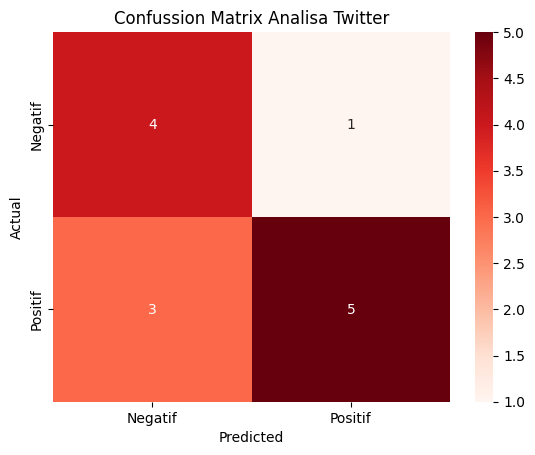

In [53]:
print(classification_report(y_test, y_pred))
print("\n")
labels = ['Negatif', 'Positif']

sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confussion Matrix Analisa Twitter')
plt.show()